In [1]:
import pandas as pd
import numpy as np

In [2]:
data = pd.read_csv("Mall_Customers.csv")
data.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [3]:
print("Shape:", data.shape)
print("\nMissing values:")
print(data.isnull().sum())

Shape: (200, 5)

Missing values:
CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [4]:
data.head()

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [5]:
from sklearn.cluster import KMeans

In [6]:
x = data[["Annual Income (k$)", "Spending Score (1-100)"]]

In [7]:
k_cluster = KMeans(n_clusters=3)
k_cluster.fit(x)

F:\setup\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


,n_clusters,3
,init,'k-means++'
,n_init,'auto'
,max_iter,300
,tol,0.0001
,verbose,0
,random_state,None
,copy_x,True
,algorithm,'lloyd'


In [8]:
prediction = k_cluster.predict(x)

In [9]:
print(prediction)

[1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2
 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2 0
 2 0 2 0 2 0 2 0 2 0 2 0 2 0 2]


In [10]:
import matplotlib.pyplot as plt

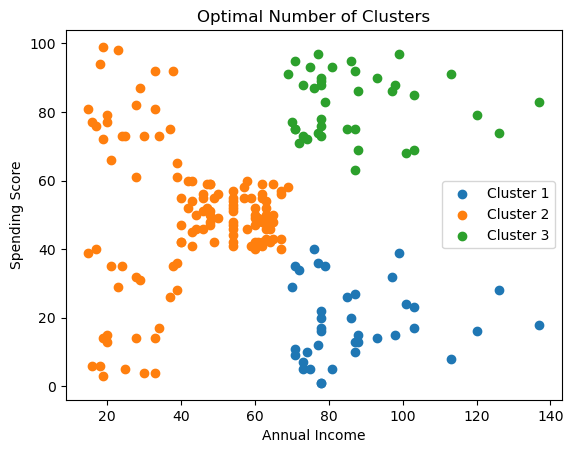

In [19]:
for i in range(3):
    plt.scatter(x["Annual Income (k$)"][prediction == i],
                x["Spending Score (1-100)"][prediction == i],
                label=f"Cluster {i+1}")

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Optimal Number of Clusters")
plt.legend()
plt.show()


F:\setup\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
F:\setup\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
F:\setup\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
F:\setup\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. Y

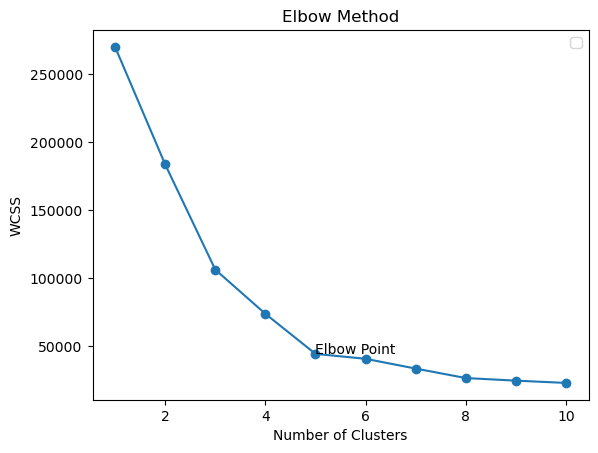

In [25]:
wcss = []

for i in range(1, 11):
    model = KMeans(n_clusters=i, random_state=42)
    model.fit(x)
    wcss.append(model.inertia_)

plt.plot(range(1, 11), wcss, marker='o')
plt.xlabel("Number of Clusters")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.annotate("Elbow Point", (5, wcss[4]))

plt.legend()
plt.show()


In [20]:
annual_income = float(input("Enter Annual Income (k$): "))
spending_score = float(input("Enter Spending Score (1-100): "))

new_customer = np.array([[annual_income, spending_score]])

predicted_cluster = k_cluster.predict(new_customer)

print("Predicted Cluster:", predicted_cluster[0])

Enter Annual Income (k$):  15
Enter Spending Score (1-100):  40


Predicted Cluster: 1


F:\setup\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but KMeans was fitted with feature names
  warnings.warn(


In [26]:
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering

In [29]:
hc = AgglomerativeClustering(n_clusters=3, linkage="ward")
prediction_hc = hc.fit_predict(x)
print(prediction_hc)

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 2 0 2 0 2 1 2 1 2 0 2 1 2 1 2 1 2 1 2 0 2 1 2 0 2
 1 2 1 2 1 2 1 2 1 2 1 2 0 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2 1
 2 1 2 1 2 1 2 1 2 1 2 1 2 1 2]


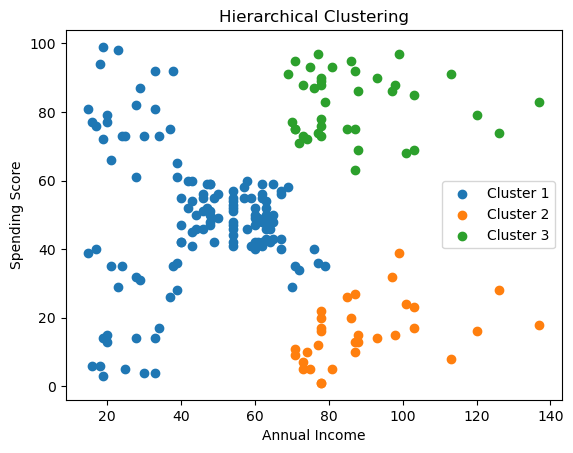

In [30]:
for i in range(3):
    plt.scatter(
        x["Annual Income (k$)"][prediction_hc == i],
        x["Spending Score (1-100)"][prediction_hc == i],
        label=f"Cluster {i+1}"
    )

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Hierarchical Clustering")
plt.legend()
plt.show()


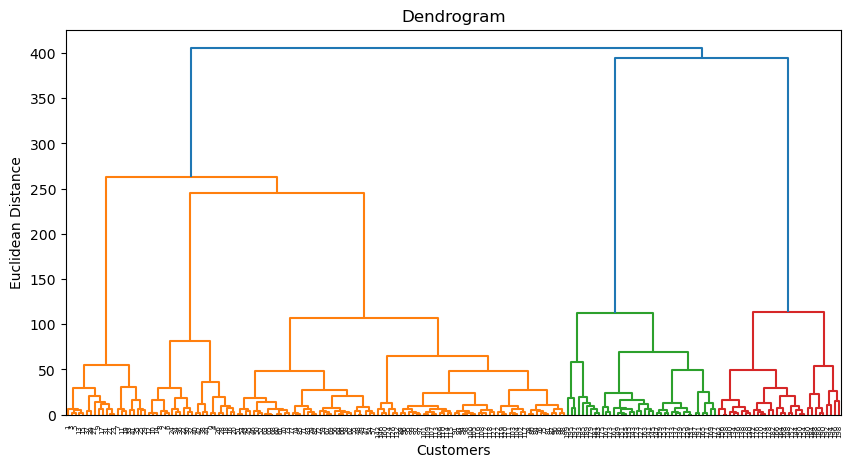

In [32]:
plt.figure(figsize=(10, 5))

dendrogram(linkage(x, method="ward"))

plt.title("Dendrogram")
plt.xlabel("Customers")
plt.ylabel("Euclidean Distance")
plt.show()


In [33]:
hc_means = x.groupby(prediction_hc).mean()

In [35]:
annual_income = float(input("Enter Annual Income (k$): "))
spending_score = float(input("Enter Spending Score (1-100): "))
new_customer = np.array([annual_income, spending_score])

distances = np.sqrt(((hc_means.values - new_customer) ** 2).sum(axis=1))
cluster = hc_means.index[np.argmin(distances)]

print("Predicted Cluster:", cluster + 1)

Enter Annual Income (k$):  15
Enter Spending Score (1-100):  40


Predicted Cluster: 1
